# Análisis Exploratorio de Datos y Preprocesamiento

Se utilizó el conjunto de datos *Online Shoppers Purchasing Intention*, que contiene 12,330 sesiones de navegación y 18 variables relacionadas con la actividad de los visitantes en un sitio de comercio electrónico.

El objetivo del análisis es conocer las características de las sesiones, identificar patrones de navegación, revisar la calidad de los datos y preparar la información para aplicar modelos de minería de datos.

Este Notebook contiene 2 etapas:

- **Análisis exploratorio de datos (EDA):** revisión de las distribuciones, frecuencias, valores atípicos, correlaciones y relaciones con la variable `Revenue`.
- **Preprocesamiento:** revisión de consistencia, tratamiento de duplicados y generación de nuevas características para el modelado.

Se conservará una copia del conjunto original y se utilizará una versión de trabajo sin las 125 filas duplicadas adicionales, formada por 12,205 sesiones.

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from pathlib import Path


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
ruta_archivo = '/content/drive/MyDrive/mineriaDatos/'
df = pd.read_csv(f'{ruta_archivo}online_shoppers_intention.csv')
df


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.000000,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.000000,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.000000,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12325,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6,1,1,Returning_Visitor,True,False
12326,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False
12327,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2,1,13,Returning_Visitor,True,False
12328,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2,3,11,Returning_Visitor,False,False


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [ ]:
# Revisión de valores faltantes
faltantes = pd.DataFrame({
    'Cantidad': df.isna().sum()
})

display(faltantes)

print("Total de valores faltantes:", df.isna().sum().sum())

,Cantidad
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


Total de valores faltantes: 0


Se revisaron las 18 variables del conjunto original y no se encontraron valores faltantes. Por lo tanto, no fue necesario aplicar métodos de imputación ni eliminar registros por ausencia de información.

In [ ]:
# encontrar duplicados
print("Regirstros duplicados : ", df.duplicated().sum())
df[df.duplicated(keep=False)]

Regirstros duplicados :  125


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
85,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
132,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11934,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,2,New_Visitor,False,False
11938,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,4,1,Returning_Visitor,True,False
12159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,3,Returning_Visitor,False,False
12180,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,13,9,20,Returning_Visitor,False,False


In [ ]:
df_original = df.copy()

In [ ]:
# eliminar registros duplicados
renglones_antes = len(df)
df = df.drop_duplicates(keep="first").reset_index(drop=True)
renglones_despues = len(df)
print(f"Renglones antes: {renglones_antes}")
print(f"Renglones despues: {renglones_despues}")
print(f"Renglones eliminados: {renglones_antes - renglones_despues}")

Renglones antes: 12205
Renglones despues: 12205
Renglones eliminados: 0


### Observaciones sobre registros duplicados

Se identificaron 125 filas adicionales idénticas a registros anteriores. Para el análisis se conservaron las 12,330 sesiones originales en `df_original` y se creó una versión de trabajo con 12,205 sesiones.

La eliminación de estas filas permite evitar que registros idénticos tengan una influencia repetida en los modelos.

Sin embargo, como el dataset no incluye un identificador único de sesión, no es posible asegurar que todos los registros idénticos sean errores. Por ello, se conserva también la versión original como referencia.

## Validación de consistencia de los datos

In [ ]:
# Variables que no deberían contener valores negativos
columnas_no_negativas = [
    'Administrative', 'Administrative_Duration',
    'Informational', 'Informational_Duration',
    'ProductRelated', 'ProductRelated_Duration',
    'PageValues'
]

print("Valores negativos:")
for v in columnas_no_negativas:
    print(v, ":", (df[v] < 0).sum())

print("\nValores fuera del rango permitido:")
for v in ['BounceRates', 'ExitRates', 'SpecialDay']:
    print(v, ":", (~df[v].between(0, 1)).sum())

print("\nValores infinitos:")
print(np.isinf(df.select_dtypes(include=np.number)).sum().sum())

# Revisar coherencia entre páginas y duración
for paginas, duracion in [
    ('Administrative', 'Administrative_Duration'),
    ('Informational', 'Informational_Duration'),
    ('ProductRelated', 'ProductRelated_Duration')
]:
    inconsistentes = (
        (df[paginas] == 0) & (df[duracion] > 0)
    ).sum()

    print(f"{paginas}: {inconsistentes} inconsistencias")

Valores negativos:
Administrative : 0
Administrative_Duration : 0
Informational : 0
Informational_Duration : 0
ProductRelated : 0
ProductRelated_Duration : 0
PageValues : 0

Valores fuera del rango permitido:
BounceRates : 0
ExitRates : 0
SpecialDay : 0

Valores infinitos:
0
Administrative: 0 inconsistencias
Informational: 0 inconsistencias
ProductRelated: 0 inconsistencias


### Observaciones de la validación de consistencia

Se verificó que las variables numéricas analizadas no presentaran valores negativos ni infinitos. También se comprobó que `BounceRates`, `ExitRates` y `SpecialDay` se encontraran dentro del intervalo permitido de 0 a 1.

Además, se revisó la coherencia entre el número de páginas visitadas y los tiempos de navegación registrados.

No se encontraron inconsistencias según las reglas utilizadas, por lo que no fue necesario realizar correcciones adicionales durante esta etapa.

## **Análisis exploratorio de datos y preprocesamiento de datos**
Separar variables numéricas y categóricas

# Descripcion de variables

| Variable | Descripción |
|---|---|
| `Administrative` | Número de páginas administrativas visitadas. |
| `Administrative_Duration` | Tiempo en páginas administrativas, en segundos. |
| `Informational` | Número de páginas informativas visitadas. |
| `Informational_Duration` | Tiempo en páginas informativas, en segundos. |
| `ProductRelated` | Número de páginas de productos visitadas. |
| `ProductRelated_Duration` | Tiempo en páginas de productos, en segundos. |
| `BounceRates` | Tasa de rebote. |
| `ExitRates` | Tasa de salida. |
| `PageValues` | Valor promedio atribuido a páginas visitadas antes de una transacción. |
| `SpecialDay` | Proximidad a un día comercial especial, entre 0 y 1. |
| `Month` | Mes de la sesión. |
| `OperatingSystems` | Código del sistema operativo. |
| `Browser` | Código del navegador. |
| `Region` | Código de la región. |
| `TrafficType` | Código del tipo de tráfico. |
| `VisitorType` | Tipo de visitante. |
| `Weekend` | Indica si la sesión ocurrió en fin de semana. |
| `Revenue` | Variable objetivo: indica si la sesión terminó en compra. |


In [ ]:
# hacemos SpecialDay un valor categorico ordinal
df['SpecialDay'] = pd.Categorical(
    df['SpecialDay'],
    categories=[0,0.2,0.4,0.6,0.8,1],
    ordered=True
)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12205 entries, 0 to 12204
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   Administrative           12205 non-null  int64   
 1   Administrative_Duration  12205 non-null  float64 
 2   Informational            12205 non-null  int64   
 3   Informational_Duration   12205 non-null  float64 
 4   ProductRelated           12205 non-null  int64   
 5   ProductRelated_Duration  12205 non-null  float64 
 6   BounceRates              12205 non-null  float64 
 7   ExitRates                12205 non-null  float64 
 8   PageValues               12205 non-null  float64 
 9   SpecialDay               12205 non-null  category
 10  Month                    12205 non-null  object  
 11  OperatingSystems         12205 non-null  int64   
 12  Browser                  12205 non-null  int64   
 13  Region                   12205 non-null  int64   
 14  Traffi

In [ ]:
# Verificamos su cambio
df['SpecialDay'].dtype

print("Tipo de dato:", df['SpecialDay'].dtype)
print("Valores faltantes:", df['SpecialDay'].isna().sum())

print("\nFrecuencia de cada nivel:")
display(df['SpecialDay'].value_counts().sort_index())

Tipo de dato: category
Valores faltantes: 0

Frecuencia de cada nivel:


,count
SpecialDay,
0.0,10956
0.2,178
0.4,243
0.6,350
0.8,324
1.0,154


### Tratamiento de SpecialDay

La variable `SpecialDay` representa un indicador de proximidad a fechas comerciales especiales mediante valores entre 0 y 1.

Para el análisis exploratorio se decidió tratarla como una variable categórica ordinal, debido a que contiene seis niveles definidos y ordenados.

Esta transformación permite comparar las frecuencias y el comportamiento de compra entre los diferentes niveles, sin modificar su significado original.

El valor 0 representa el nivel mínimo del indicador y no necesariamente significa que la sesión ocurrió fuera de cualquier periodo comercial importante.

In [ ]:
variables_numericas = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration','ProductRelated', 'ProductRelated_Duration','BounceRates','ExitRates',
                       'PageValues']
variables_categoricas = ['Month', 'OperatingSystems','Browser', 'Region','TrafficType','VisitorType','Weekend', 'Revenue','SpecialDay']

In [ ]:
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,OperatingSystems,Browser,Region,TrafficType
count,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000
mean,2.338878,81.646331,0.508726,34.825454,32.045637,1206.982457,0.020370,0.041466,5.949574,2.124211,2.357804,3.153298,4.073904
std,3.330436,177.491845,1.275617,141.424807,44.593649,1919.601400,0.045255,0.046163,18.653671,0.906823,1.710114,2.402340,4.016654
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,8.000000,193.000000,0.000000,0.014231,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,9.000000,0.000000,0.000000,18.000000,608.942857,0.002899,0.025000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,94.700000,0.000000,0.000000,38.000000,1477.154762,0.016667,0.048529,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,8.000000,13.000000,9.000000,20.000000


## Análisis univariado de las variables numéricas

### Estadísticas descriptivas

In [ ]:
df[variables_numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12205.0,2.338878,3.330436,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12205.0,81.646331,177.491845,0.0,0.000000,9.000000,94.700000,3398.750000
Informational,12205.0,0.508726,1.275617,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12205.0,34.825454,141.424807,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12205.0,32.045637,44.593649,0.0,8.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12205.0,1206.982457,1919.601400,0.0,193.000000,608.942857,1477.154762,63973.522230
BounceRates,12205.0,0.020370,0.045255,0.0,0.000000,0.002899,0.016667,0.200000
ExitRates,12205.0,0.041466,0.046163,0.0,0.014231,0.025000,0.048529,0.200000
PageValues,12205.0,5.949574,18.653671,0.0,0.000000,0.000000,0.000000,361.763742


### Observaciones de las variables numéricas

- **`ProductRelated_Duration`:** El tiempo promedio acumulado en páginas de productos fue de 1,206.98 segundos (aproximadamente 20.12 minutos) por sesión, mientras que la mediana fue de 608.94 segundos (10.15 minutos). Indica una distribución asimétrica hacia la derecha, donde algunas sesiones de duración elevada incrementan el promedio.

- **`ProductRelated`:** Se visitaron aproximadamente 32.05 páginas de productos en promedio por sesión, mientras que la mediana fue de 18 páginas.

- **`BounceRates`:** La tasa de rebote promedio fue de 0.02037 (2.04 %), mientras que `ExitRates` presentó un promedio de 0.04147 (4.15 %). Ambas variables se concentran principalmente en valores bajos.

- **`Informational` e `Informational_Duration`:** Ambas variables presentan una mediana de cero, lo que indica que al menos la mitad de las sesiones no registró visitas ni tiempo de navegación en páginas informativas.

## Análisis univariado de las variables categóricas

### Frecuencias y porcentajes

In [ ]:
df[variables_categoricas].describe(include='all')

,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,SpecialDay
count,12205,12205.000000,12205.000000,12205.000000,12205.000000,12205,12205,12205,12205.0
unique,10,NaN,NaN,NaN,NaN,3,2,2,6.0
top,May,NaN,NaN,NaN,NaN,Returning_Visitor,False,False,0.0
freq,3329,NaN,NaN,NaN,NaN,10431,9346,10297,10956.0
mean,NaN,2.124211,2.357804,3.153298,4.073904,NaN,NaN,NaN,NaN
std,NaN,0.906823,1.710114,2.402340,4.016654,NaN,NaN,NaN,NaN
min,NaN,1.000000,1.000000,1.000000,1.000000,NaN,NaN,NaN,NaN
25%,NaN,2.000000,2.000000,1.000000,2.000000,NaN,NaN,NaN,NaN
50%,NaN,2.000000,2.000000,3.000000,2.000000,NaN,NaN,NaN,NaN
75%,NaN,3.000000,2.000000,4.000000,4.000000,NaN,NaN,NaN,NaN


In [ ]:
# Identificar valores unicos
# unique regresa valores unicos ,como el distinct en sql
for v in variables_categoricas:
  print(f"Valores unicos de {v}")
  print(df[v].unique())

Valores unicos de Month
['Feb' 'Mar' 'May' 'Oct' 'June' 'Jul' 'Aug' 'Nov' 'Sep' 'Dec']
Valores unicos de OperatingSystems
[1 2 4 3 7 6 8 5]
Valores unicos de Browser
[ 1  2  3  4  5  6  7 10  8  9 12 13 11]
Valores unicos de Region
[1 9 2 3 4 5 6 7 8]
Valores unicos de TrafficType
[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 18 19 16 17 20]
Valores unicos de VisitorType
['Returning_Visitor' 'New_Visitor' 'Other']
Valores unicos de Weekend
[False  True]
Valores unicos de Revenue
[False  True]
Valores unicos de SpecialDay
[0.0, 0.4, 0.8, 1.0, 0.2, 0.6]
Categories (6, float64): [0.0 < 0.2 < 0.4 < 0.6 < 0.8 < 1.0]


### Observaciones de las variables categóricas

- **`SpecialDay`:** El valor 0 fue el más frecuente, con 10,956 sesiones (89.77 %). Esto indica que la mayoría de las sesiones registró el nivel mínimo del indicador de cercanía a una fecha comercial especial.

- Se identificaron seis valores posibles para esta variable: 0, 0.2, 0.4, 0.6, 0.8 y 1. Por ello, en este análisis se representó como una variable categórica ordinal, conservando el orden de sus niveles.

In [ ]:
# Frecuencias y porcentajes de variables categóricas
for v in variables_categoricas:
    tabla = pd.DataFrame({
        'Frecuencia': df[v].value_counts(),
        'Porcentaje (%)': df[v].value_counts(normalize=True) * 100
    })

    print(f"\nVariable: {v}")
    display(tabla.round(2))


Variable: Month


,Frecuencia,Porcentaje (%)
Month,,
May,3329,27.28
Nov,2982,24.43
Mar,1860,15.24
Dec,1706,13.98
Oct,549,4.50
Sep,448,3.67
Aug,433,3.55
Jul,432,3.54
June,285,2.34



Variable: OperatingSystems


,Frecuencia,Porcentaje (%)
OperatingSystems,,
2,6541,53.59
1,2549,20.88
3,2530,20.73
4,478,3.92
8,75,0.61
6,19,0.16
7,7,0.06
5,6,0.05



Variable: Browser


,Frecuencia,Porcentaje (%)
Browser,,
2,7883,64.59
1,2427,19.89
4,731,5.99
5,465,3.81
6,174,1.43
10,163,1.34
8,135,1.11
3,105,0.86
13,56,0.46


... (8 outputs left out)


Variable: Revenue


,Frecuencia,Porcentaje (%)
Revenue,,
False,10297,84.37
True,1908,15.63



Variable: SpecialDay


,Frecuencia,Porcentaje (%)
SpecialDay,,
0.0,10956,89.77
0.6,350,2.87
0.8,324,2.65
0.4,243,1.99
0.2,178,1.46
1.0,154,1.26


## Distribución de la variable objetivo: Revenue

,Sesiones,Porcentaje (%)
Revenue,,
False,10297,84.37
True,1908,15.63


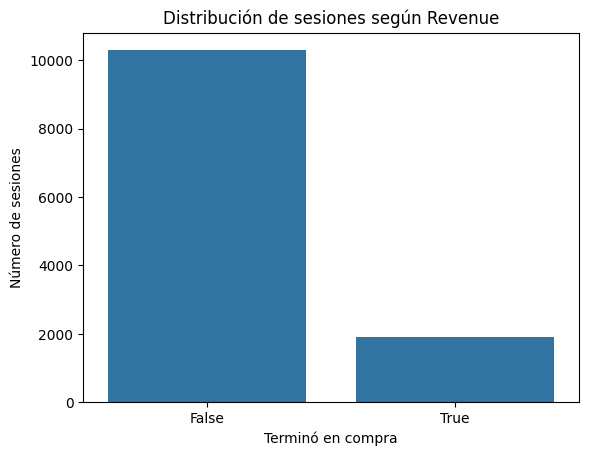

In [ ]:
# Distribución de Revenue en el dataset de trabajo
frecuencias = df['Revenue'].value_counts()
porcentajes = df['Revenue'].value_counts(normalize=True) * 100

tabla_revenue = pd.DataFrame({
    'Sesiones': frecuencias,
    'Porcentaje (%)': porcentajes
})

display(tabla_revenue.round(2))

sns.countplot(data=df, x='Revenue')
plt.title('Distribución de sesiones según Revenue')
plt.xlabel('Terminó en compra')
plt.ylabel('Número de sesiones')
plt.show()

### Observaciones sobre Revenue

La variable `Revenue` indica si una sesión de navegación terminó en compra.

Se observa que las sesiones sin compra representan la mayor parte del conjunto de datos, por lo que existe un desbalance entre ambas clases.

Este resultado es importante para los modelos de clasificación, ya que una evaluación basada únicamente en la exactitud podría resultar insuficiente. Por ello, será necesario utilizar también métricas como precisión, recall y F1-score.

## Histogramas de variables numéricas

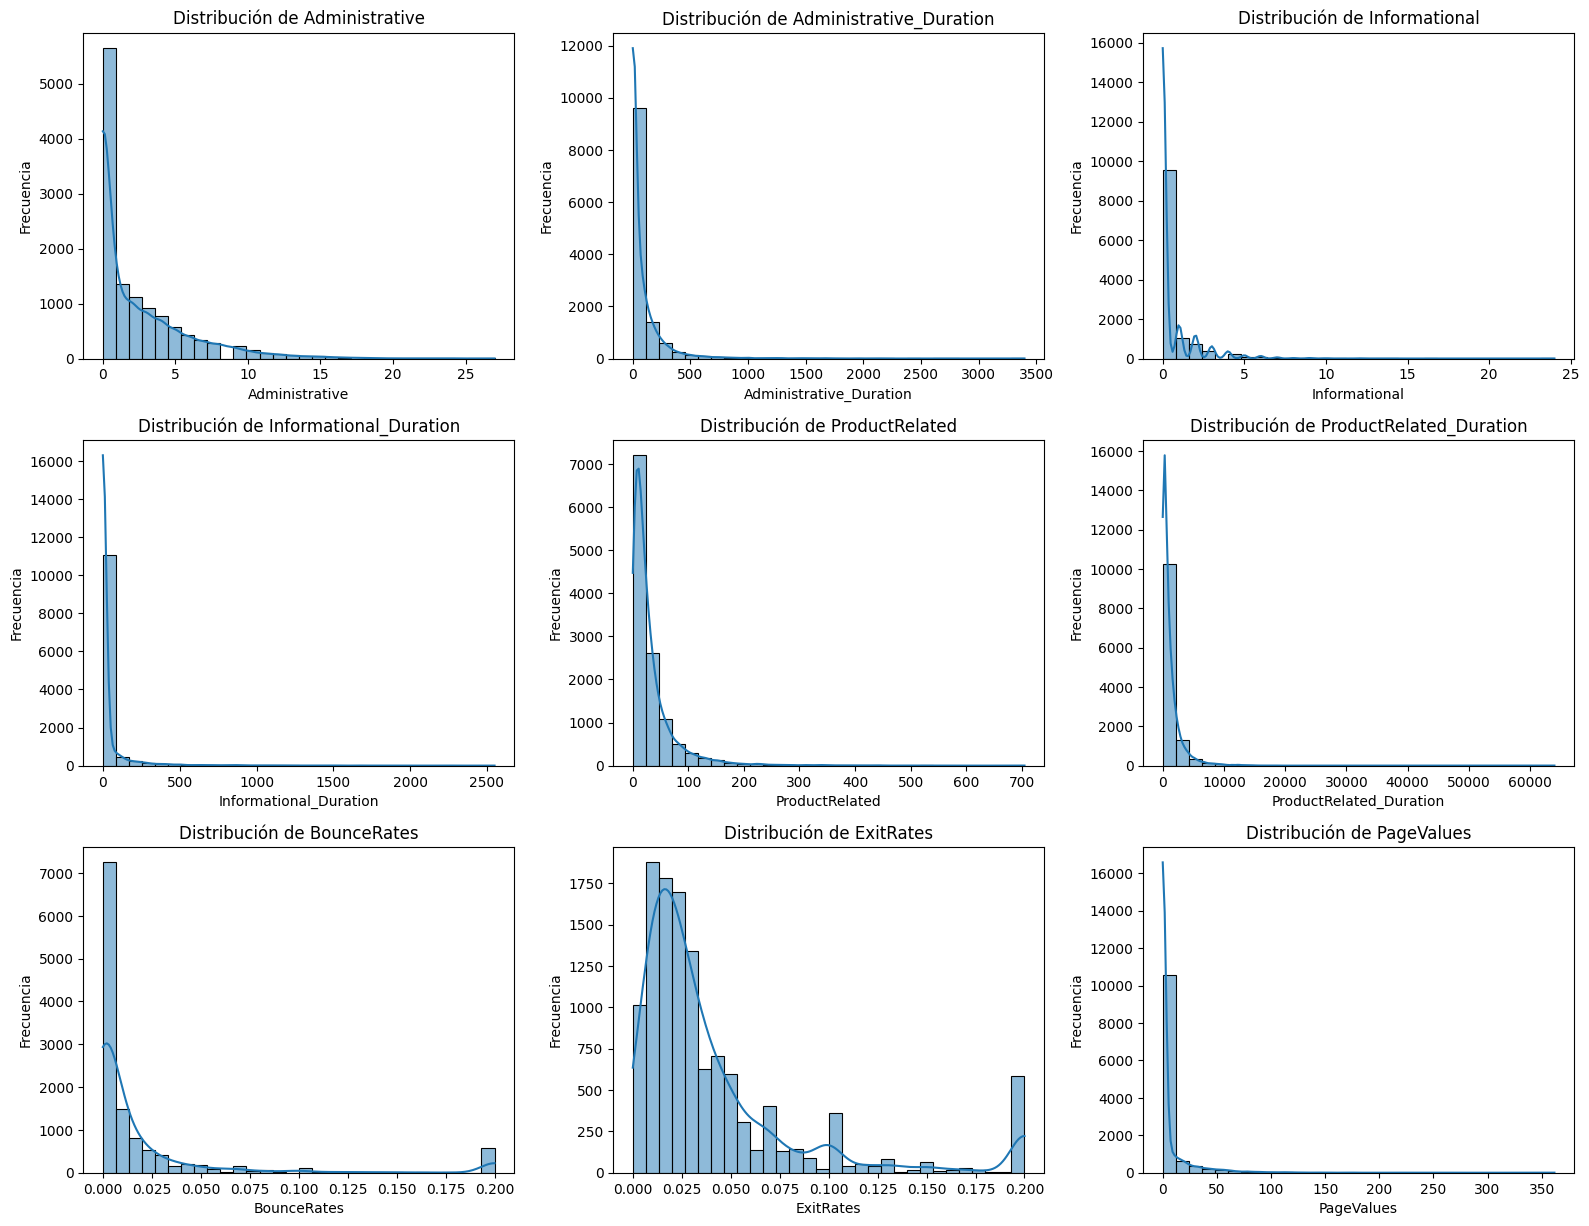

In [ ]:
# Histogramas de varibles numericas con distribucion
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
axes = axes.flatten()

for i, v in enumerate(variables_numericas):
    sns.histplot(df[v], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribución de {v}')
    axes[i].set_xlabel(v)
    axes[i].set_ylabel('Frecuencia')

for j in range(len(variables_numericas), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Observaciones de los histogramas

Los histogramas muestran que varias variables numéricas presentan distribuciones asimétricas hacia la derecha, con una mayor concentración de sesiones en valores bajos.

En `Administrative` e `Informational`, la mayoría de las sesiones registra pocas páginas visitadas. Esta tendencia también se observa en las variables correspondientes a sus tiempos de navegación.

En `ProductRelated` y `ProductRelated_Duration`, algunas sesiones presentan una actividad considerablemente mayor que el resto, lo que genera una distribución con una cola prolongada hacia la derecha.

Por otra parte, `BounceRates` y `ExitRates` concentran una proporción importante de sus valores cerca de cero. `PageValues` también presenta una acumulación elevada de registros en cero.

Estas distribuciones permiten identificar diferencias entre el comportamiento habitual de navegación y las sesiones que presentan valores elevados.

# Gráficas de barras de variables categóricas

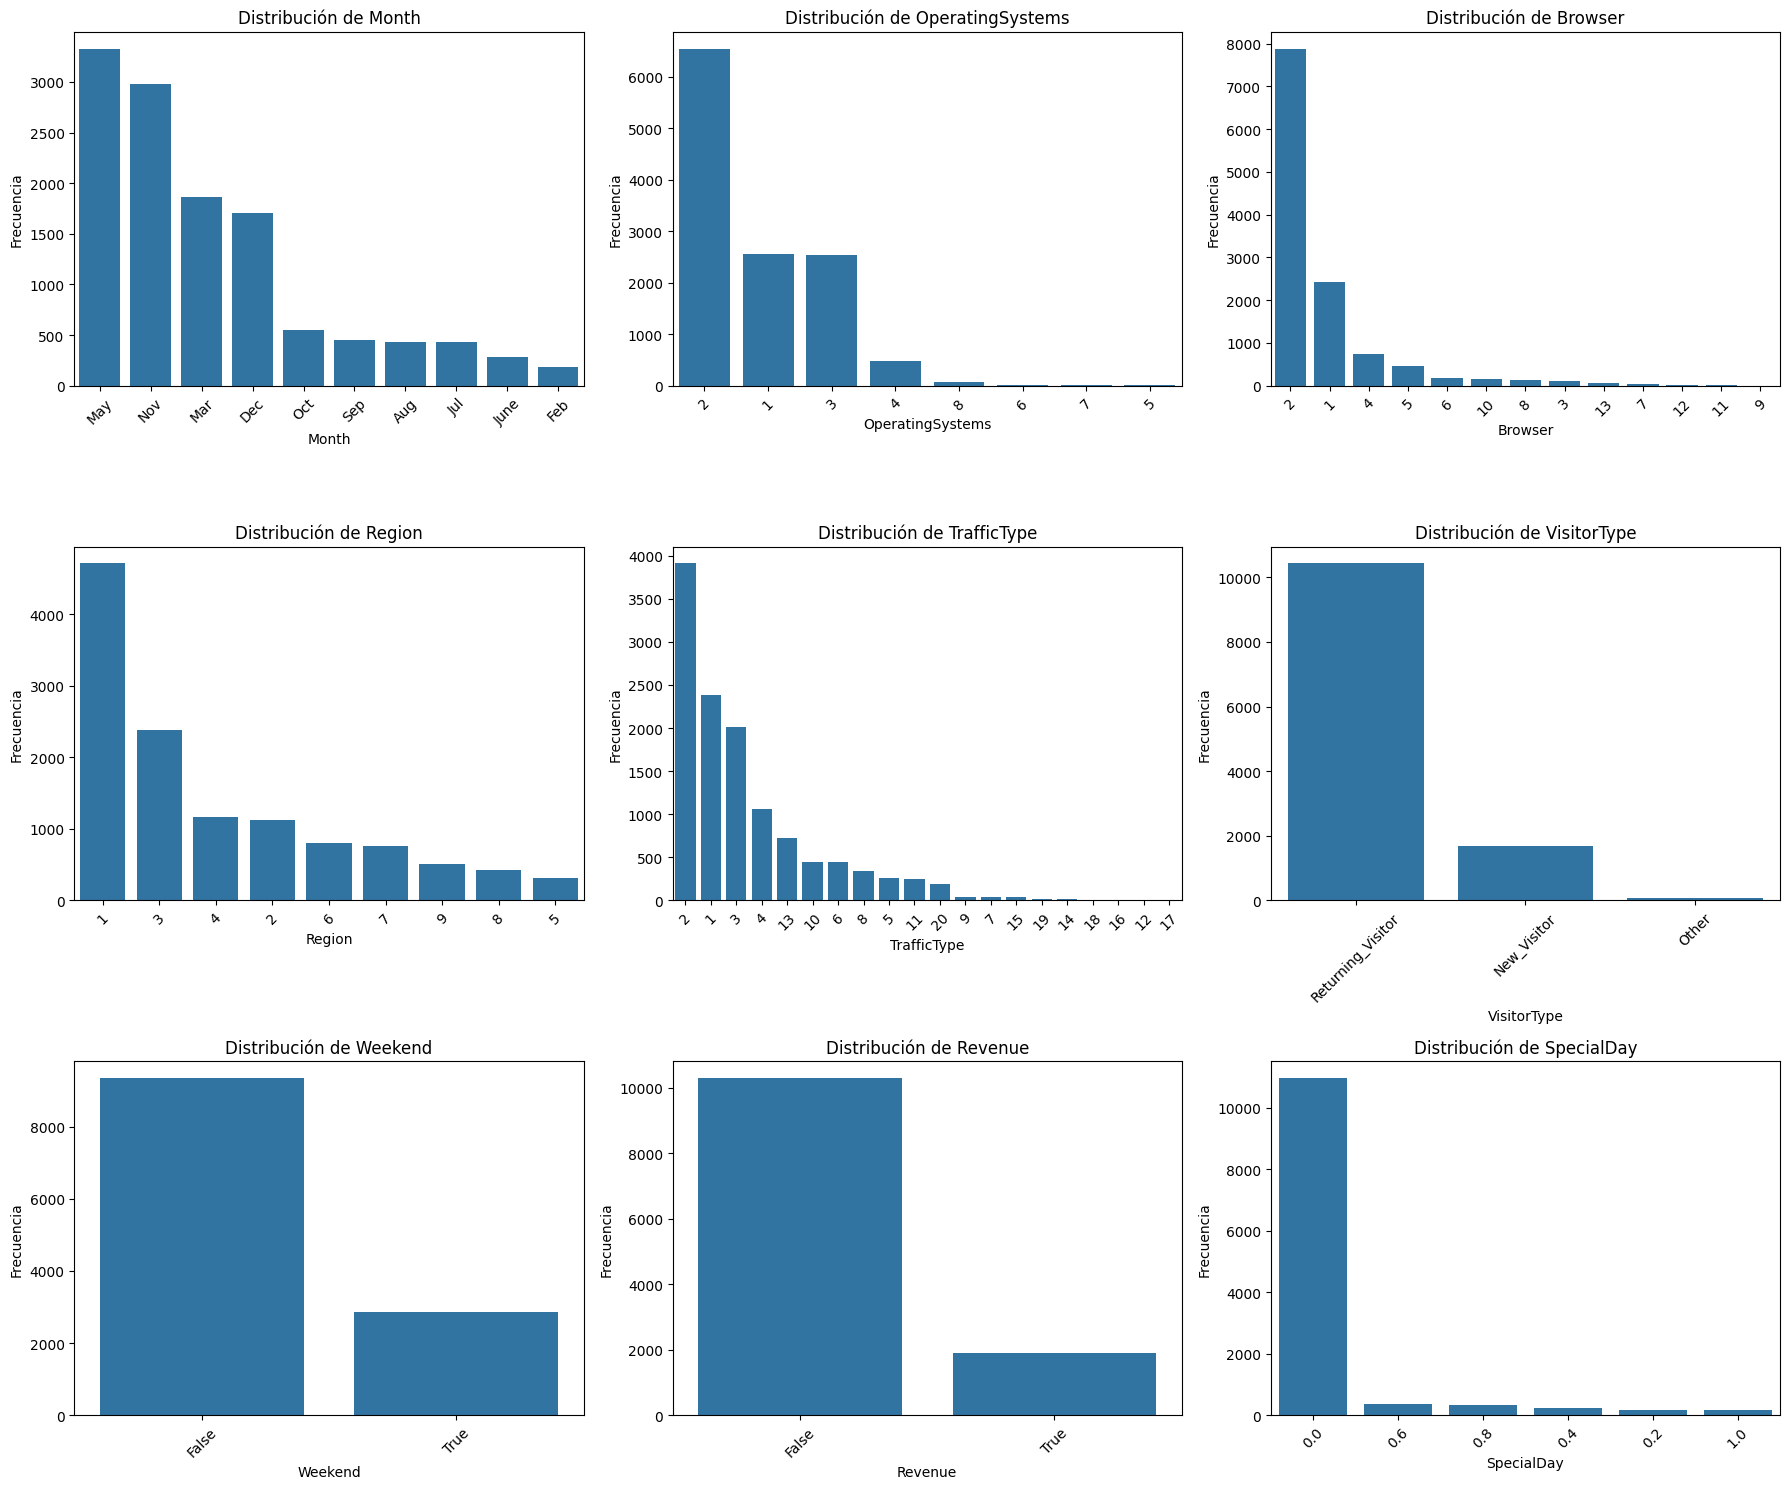

In [ ]:
# Gráficas de barras de variables categóricas
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()

for i, v in enumerate(variables_categoricas):
    orden = df[v].value_counts().index

    sns.countplot(
        data=df,
        x=v,
        order=orden,
        ax=axes[i]
    )

    axes[i].set_title(f'Distribución de {v}')
    axes[i].set_xlabel(v)
    axes[i].set_ylabel('Frecuencia')
    axes[i].tick_params(axis='x', rotation=45)

for j in range(len(variables_categoricas), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Observaciones de las gráficas de barras de variables categóricas

Se analizaron las frecuencias de nueve variables categóricas para identificar las categorías con mayor presencia en las sesiones de navegación.

**1. Mes (`Month`):** Mayo y noviembre concentran la mayor cantidad de sesiones, con 27.28 % y 24.43 %, respectivamente. Febrero y junio presentan las frecuencias más bajas.

**2. Sistema operativo (`OperatingSystems`):** El código 2 es el más frecuente, seguido de los códigos 1 y 3.

**3. Navegador (`Browser`):** El código 2 predomina con el 64.59 % de las sesiones, seguido del código 1. Los demás navegadores tienen frecuencias relativamente bajas.

**4. Región (`Region`):** La región 1 concentra la mayor cantidad de sesiones, con el 38.62 %, seguida de la región 3. Las demás regiones presentan una distribución más reducida.

**5. Tipo de tráfico (`TrafficType`):** El código 2 es el más frecuente, con el 32.04 % de los registros, seguido de los códigos 1 y 3. Los demás tipos de tráfico tienen una menor representación.

**6. Tipo de visitante (`VisitorType`):** Predominan las sesiones de visitantes recurrentes, con el 85.46 %, mientras que los visitantes nuevos representan el 13.87 %.

**7. Fin de semana (`Weekend`):** El 76.58 % de las sesiones ocurrió entre semana (`False`), mientras que el 23.42 % se registró durante el fin de semana (`True`).

**8. Realización de compra (`Revenue`):** El 84.37 % de las sesiones terminó sin compra (`False`), frente al 15.63 % que sí registró una compra (`True`). Esto evidencia un desbalance entre ambas clases.

**9. Fechas especiales (`SpecialDay`):** El valor 0 concentra el 89.77 % de las sesiones. Los demás niveles presentan frecuencias considerablemente menores, lo que indica un predominio del nivel mínimo de proximidad a fechas comerciales especiales.


## Diagramas de caja (Boxplots) y detección de valores atípicos

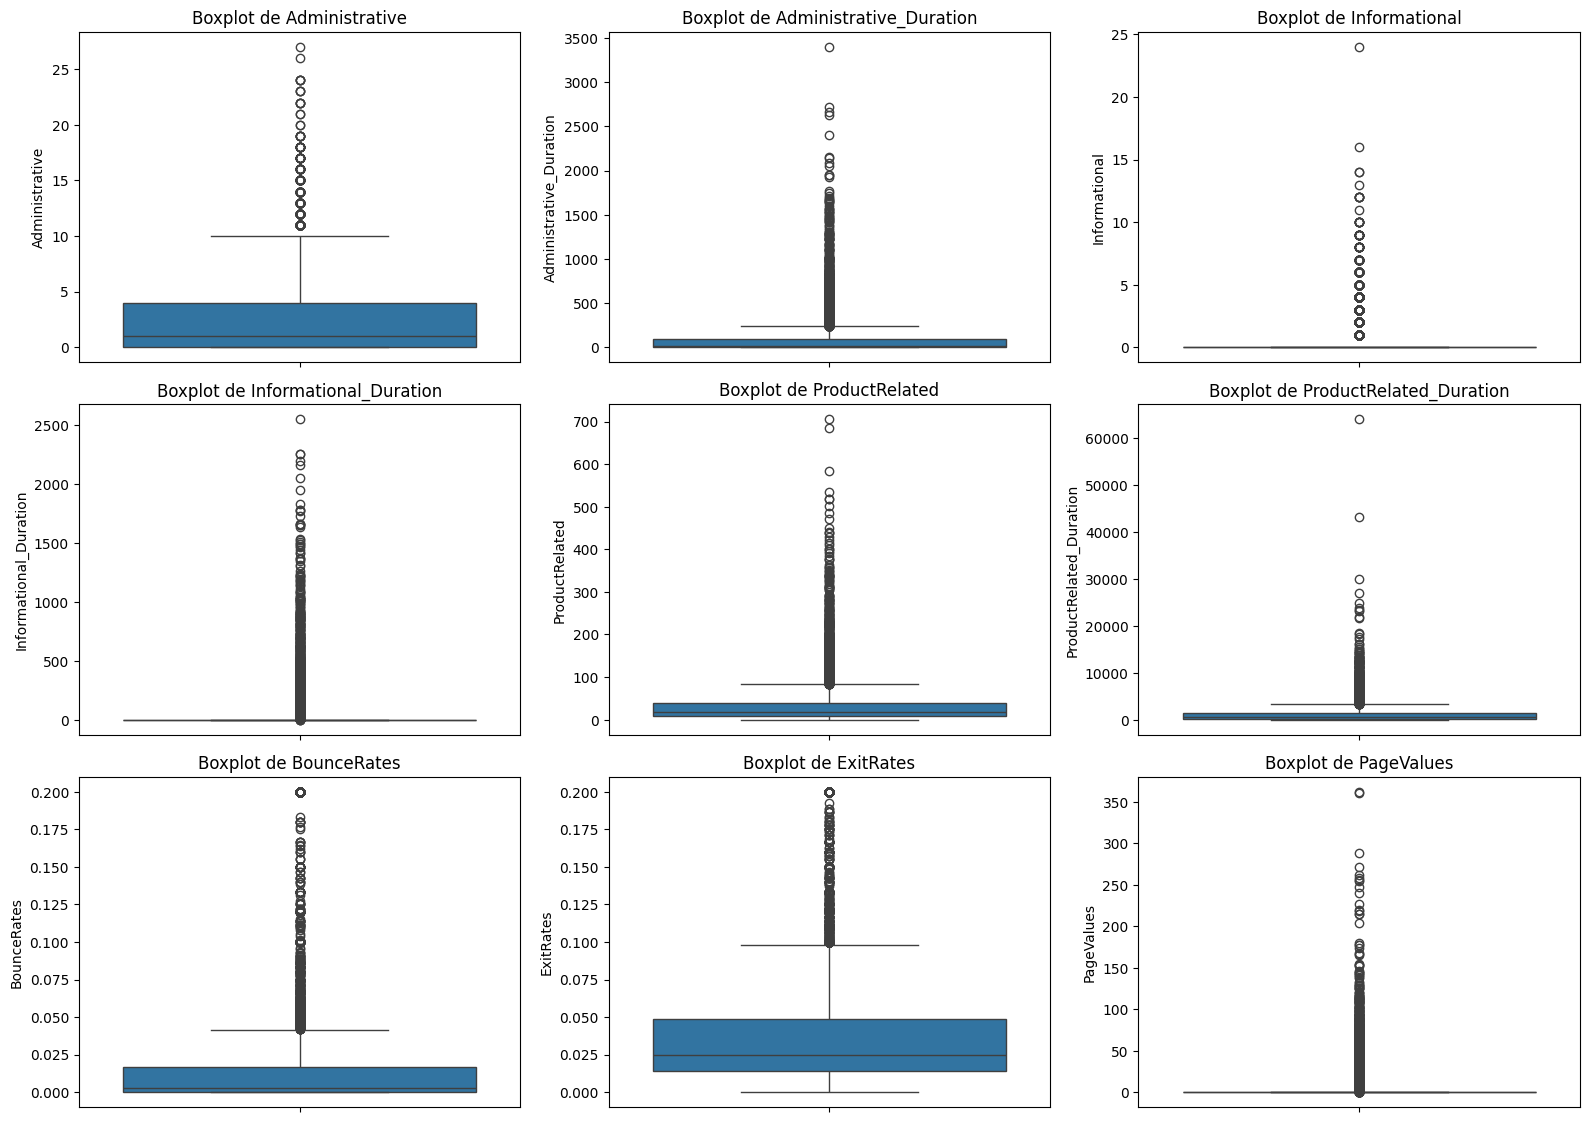

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(16, 15))
axes = axes.flatten()

for i, v in enumerate(variables_numericas):
    sns.boxplot(data=df, y=v, ax=axes[i])
    axes[i].set_title(f'Boxplot de {v}')

for j in range(len(variables_numericas), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Observaciones de los Boxplots

Los diagramas de caja muestran distribuciones asimétricas y posibles valores atípicos en distintas variables numéricas.

En `Administrative_Duration`, `ProductRelated` y `ProductRelated_Duration` se observan valores considerablemente superiores a la mayoría de las sesiones. En particular, `ProductRelated` alcanza un máximo de 705 páginas y `ProductRelated_Duration` un máximo de 63,973.52 segundos.

En `BounceRates` y `ExitRates` también aparecen valores por encima del bigote superior, con un máximo de 0.20.

Por otra parte, `Informational`, `Informational_Duration` y `PageValues` presentan el primer y tercer cuartil iguales a cero. Esto hace que los valores positivos aparezcan como posibles atípicos mediante la regla IQR, aunque no necesariamente representen errores.

Por esta razón, se decidió conservar los valores extremos, ya que podrían corresponder a comportamientos reales de navegación.

### Cuantificación de posibles valores atípicos mediante IQR

In [ ]:
resultados_iqr = []

for v in variables_numericas:
    Q1 = df[v].quantile(0.25)
    Q3 = df[v].quantile(0.75)
    IQR = Q3 - Q1

    LI = Q1 - 1.5 * IQR
    LS = Q3 + 1.5 * IQR

    outliers = (df[v] < LI) | (df[v] > LS)

    resultados_iqr.append({
        'Variable': v,
        'IQR': IQR,
        'Posibles outliers': outliers.sum(),
        'Porcentaje': outliers.mean() * 100
    })

display(pd.DataFrame(resultados_iqr).round(2))

,Variable,IQR,Posibles outliers,Porcentaje
0,Administrative,4.00,404,3.31
1,Administrative_Duration,94.70,1149,9.41
2,Informational,0.00,2631,21.56
3,Informational_Duration,0.00,2405,19.71
4,ProductRelated,30.00,1007,8.25
5,ProductRelated_Duration,1284.15,951,7.79
6,BounceRates,0.02,1428,11.70
7,ExitRates,0.03,1325,10.86
8,PageValues,0.00,2730,22.37


### Observaciones del método IQR

Se aplicó el método del rango intercuartílico para cuantificar las observaciones situadas fuera de los límites establecidos para cada variable.

Entre los resultados más relevantes se identificaron 1,149 posibles valores atípicos en `Administrative_Duration`, 1,007 en `ProductRelated`, 951 en `ProductRelated_Duration`, 1,428 en `BounceRates` y 1,325 en `ExitRates`.

También se observó que `Informational`, `Informational_Duration` y `PageValues` tienen un rango intercuartílico igual a cero. En estas variables, los valores positivos pueden ser identificados como posibles atípicos, aunque no necesariamente representen errores.

Por esta razón, se decidió conservar los valores extremos, ya que podrían representar comportamientos reales de navegación.

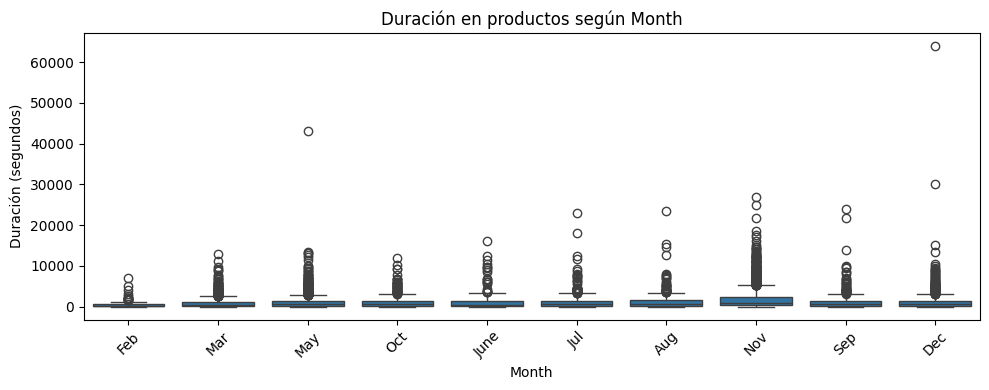

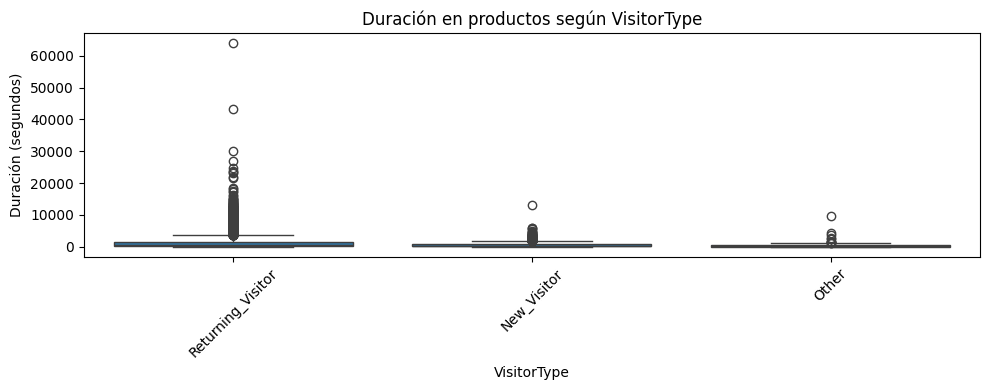

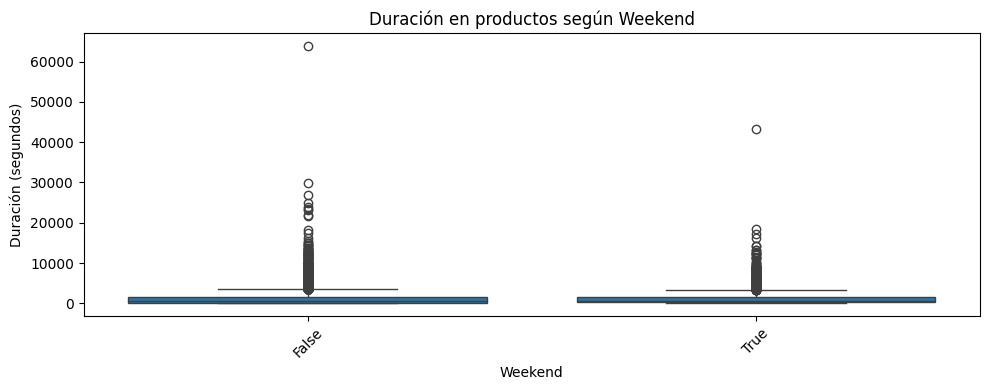

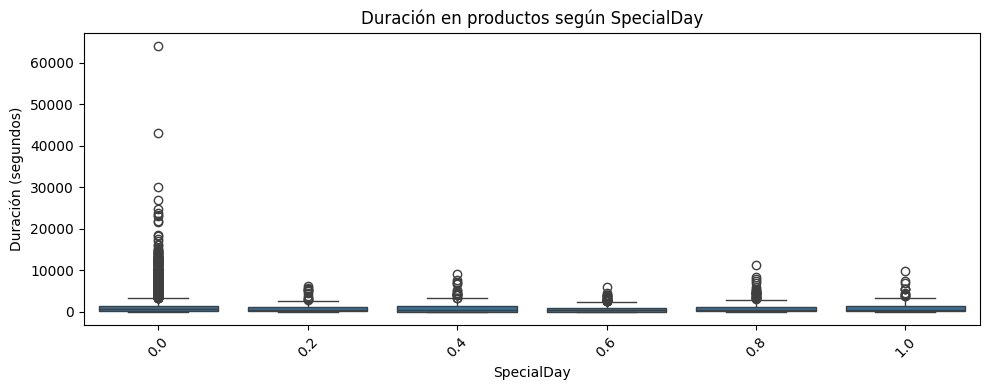

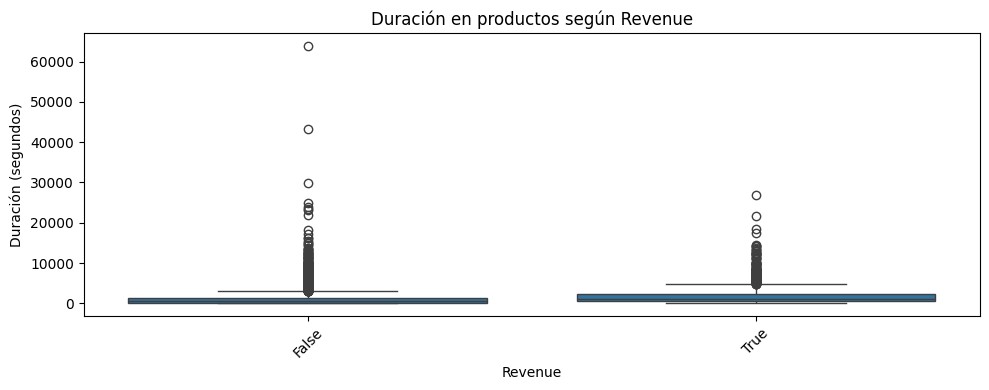

In [ ]:
# Comparar duración en productos por categoría
categorias_comparacion = [
    'Month', 'VisitorType', 'Weekend',
    'SpecialDay', 'Revenue'
]

for v in categorias_comparacion:
    plt.figure(figsize=(10, 4))

    sns.boxplot(
        data=df,
        x=v,
        y='ProductRelated_Duration'
    )

    plt.title(f'Duración en productos según {v}')
    plt.xlabel(v)
    plt.ylabel('Duración (segundos)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### Observaciones de los boxplots comparativos

Se comparó la distribución de `ProductRelated_Duration` según diferentes variables categóricas para identificar diferencias en los tiempos de navegación.

**1. Mes (`Month`):** Noviembre presenta una mayor dispersión en los tiempos de navegación, mientras que mayo y diciembre registran valores atípicos superiores a los 40,000 segundos. Esto indica que la duración de las sesiones varía entre los meses.

**2. Tipo de visitante (`VisitorType`):** Los visitantes recurrentes presentan mayor dispersión y los valores extremos más elevados, superando los 63,000 segundos. Los visitantes nuevos muestran una distribución más concentrada.

**3. Fin de semana (`Weekend`):** Las sesiones entre semana y durante el fin de semana presentan distribuciones centrales similares. Sin embargo, entre semana se registran valores extremos más elevados, sin que esto implique que todas las sesiones sean más largas.

**4. Fechas especiales (`SpecialDay`):** Las sesiones con valor 0 presentan los valores atípicos más elevados. No se observa un incremento claro en la duración conforme aumenta la proximidad a fechas especiales.

**5. Realización de compra (`Revenue`):** Las sesiones que terminaron en compra presentan tiempos de navegación generalmente mayores. No obstante, ambos grupos contienen valores atípicos, por lo que una mayor duración no garantiza una compra.

## Diagramas de dispersión

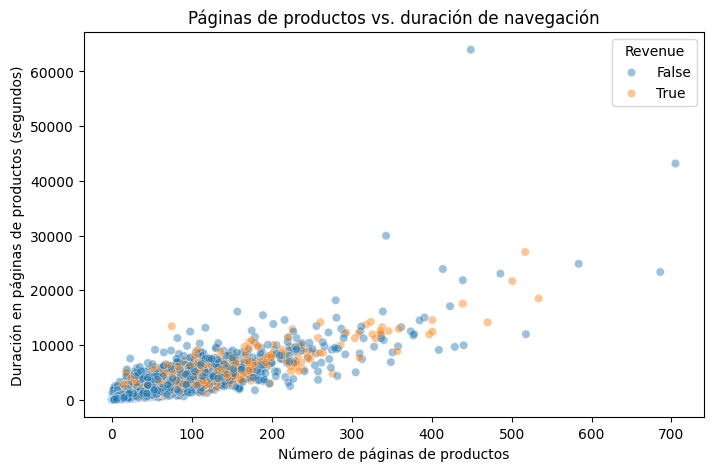

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='ProductRelated',
    y='ProductRelated_Duration',
    hue='Revenue',
    alpha=0.45
)
plt.title('Páginas de productos vs. duración de navegación')
plt.xlabel('Número de páginas de productos')
plt.ylabel('Duración en páginas de productos (segundos)')
plt.show()

### Observaciones: páginas de productos y duración

El diagrama de dispersión muestra una tendencia positiva entre `ProductRelated` y `ProductRelated_Duration`.

En general, las sesiones que consultaron una mayor cantidad de páginas de productos también registraron un mayor tiempo de navegación.

Sin embargo, las sesiones con compra y sin compra aparecen superpuestas. Esto indica que estas dos características, por sí solas, no permiten diferenciar completamente ambos resultados.

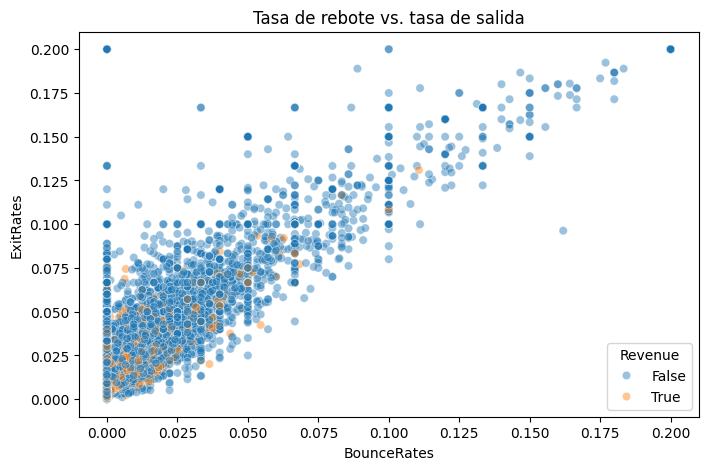

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='BounceRates',
    y='ExitRates',
    hue='Revenue',
    alpha=0.45
)

plt.title('Tasa de rebote vs. tasa de salida')
plt.xlabel('BounceRates')
plt.ylabel('ExitRates')
plt.show()

### Observaciones: tasa de rebote y tasa de salida

Se observa una tendencia positiva entre `BounceRates` y `ExitRates`, lo que indica que las sesiones con tasas de rebote más elevadas también tienden a presentar mayores tasas de salida.

La mayor parte de las sesiones que terminaron en compra se concentra en valores bajos de ambas variables, aunque en esa misma zona también se encuentran sesiones sin compra.

Esta relación coincide con la correlación elevada observada posteriormente en el mapa de calor.

## **Mapa de Calor**

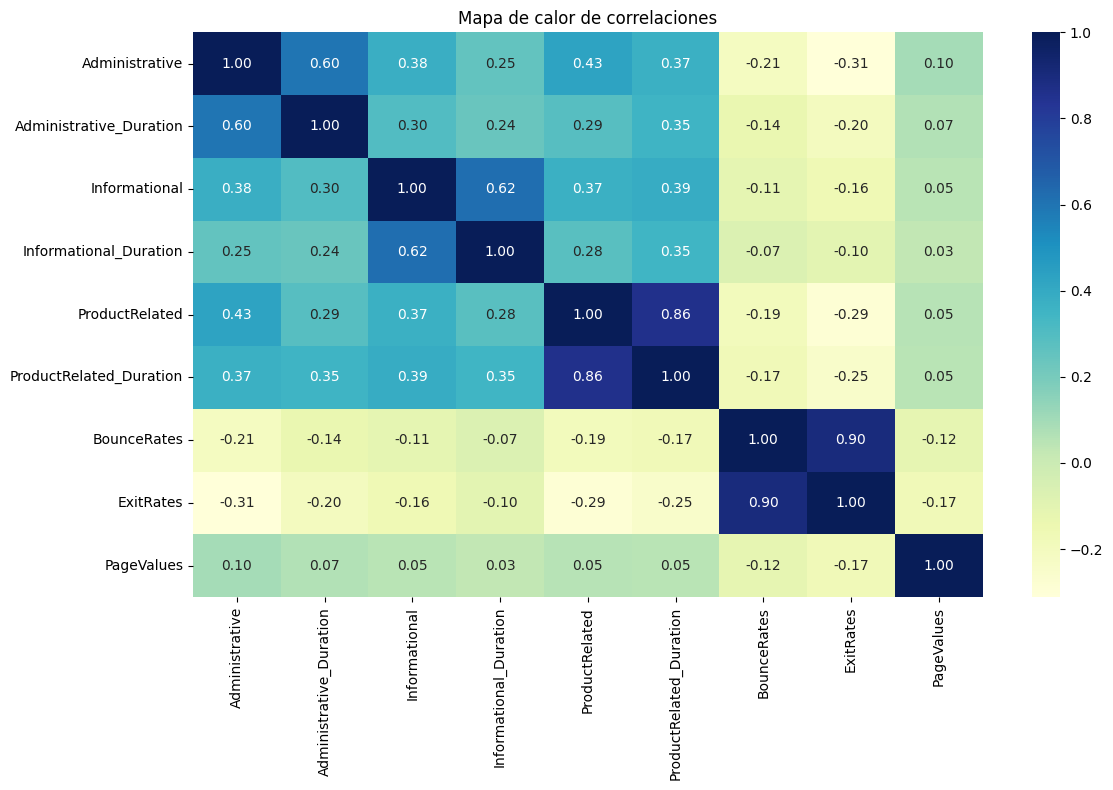

In [ ]:
# Correlación entre las variables numéricas
matriz_correlacion = df[variables_numericas].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu'
)

plt.title('Mapa de calor de correlaciones')
plt.tight_layout()
plt.show()

### Observaciones del mapa de calor

El mapa de calor permite identificar relaciones lineales entre las nueve variables numéricas analizadas mediante el coeficiente de Pearson.

La correlación más elevada entre variables distintas se presenta entre `BounceRates` y `ExitRates`, con un valor aproximado de **0.91**. Esto indica una relación **positiva fuerte** entre ambas tasas.

También se observa una correlación positiva elevada entre `ProductRelated` y `ProductRelated_Duration` (0.86), lo que confirma la relación entre la cantidad de páginas de productos consultadas y el tiempo dedicado a ellas.

Las variables informativas y administrativas también muestran correlaciones positivas entre la cantidad de páginas y sus respectivas duraciones, aunque de menor magnitud.

Por otra parte, `ExitRates` y `Administrative` presentan una correlación negativa moderada, cercana a −0.31, lo que indica que las sesiones con tasas de salida más elevadas tienden a registrar menos páginas administrativas.

La correlación describe asociaciones estadísticas y no demuestra relaciones de causa y efecto.

## Relación entre Revenue y las variables numéricas

In [ ]:
# Promedio de las variables numéricas según Revenue
promedios_revenue = (
    df.groupby('Revenue', observed=True)[variables_numericas]
    .mean()
)

display(promedios_revenue.round(2))

# Diferencia de promedios entre sesiones con y sin compra
comparacion_numericas = pd.DataFrame({
    'Sin compra': promedios_revenue.loc[False],
    'Con compra': promedios_revenue.loc[True]
})

comparacion_numericas['Diferencia'] = (
    comparacion_numericas['Con compra']
    - comparacion_numericas['Sin compra']
)

display(comparacion_numericas.round(2))

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues
Revenue,,,,,,,,,
False,2.14,74.64,0.46,30.60,29.05,1082.98,0.02,0.05,2.00
True,3.39,119.48,0.79,57.61,48.21,1876.21,0.01,0.02,27.26


,Sin compra,Con compra,Diferencia
Administrative,2.14,3.39,1.25
Administrative_Duration,74.64,119.48,44.85
Informational,0.46,0.79,0.33
Informational_Duration,30.60,57.61,27.01
ProductRelated,29.05,48.21,19.16
ProductRelated_Duration,1082.98,1876.21,793.23
BounceRates,0.02,0.01,-0.02
ExitRates,0.05,0.02,-0.03
PageValues,2.00,27.26,25.26


### Observaciones de las variables numéricas según Revenue

Al comparar las sesiones con compra y sin compra, se observaron diferencias importantes en el comportamiento de navegación.

Las sesiones con compra registraron un promedio de 48.21 páginas de productos visitadas, frente a 29.05 en las sesiones sin compra.

También presentaron un mayor tiempo promedio de navegación en páginas de productos, con 1,876.21 segundos frente a 1,082.98 segundos.

Por otra parte, las sesiones que terminaron en compra registraron menores tasas promedio de rebote y salida.

La variable `PageValues` también mostró diferencias importantes, con un promedio de 27.26 en las sesiones con compra y 2.00 en las sesiones sin compra.


In [ ]:
# Comparar variables categóricas con Revenue
for v in [c for c in variables_categoricas if c != 'Revenue']:

    tabla = pd.crosstab(
        df[v],
        df['Revenue'],
        normalize='index'
    ) * 100

    conteos = df[v].value_counts()

    tabla['Sesiones'] = conteos
    tabla = tabla.sort_values(
        by=True,
        ascending=False
    )

    print(f"\nRevenue según {v}:")
    display(tabla.round(2))


Revenue según Month:


Revenue,False,True,Sesiones
Month,,,
Nov,74.51,25.49,2982
Oct,79.05,20.95,549
Sep,80.80,19.20,448
Aug,82.45,17.55,433
Jul,84.72,15.28,432
Dec,87.34,12.66,1706
May,89.04,10.96,3329
Mar,89.68,10.32,1860
June,89.82,10.18,285



Revenue según OperatingSystems:


Revenue,False,True,Sesiones
OperatingSystems,,,
8,77.33,22.67,75
4,82.22,17.78,478
2,82.34,17.66,6541
5,83.33,16.67,6
1,85.13,14.87,2549
7,85.71,14.29,7
3,89.41,10.59,2530
6,89.47,10.53,19



Revenue según Browser:


Revenue,False,True,Sesiones
Browser,,,
12,70.00,30.00,10
13,71.43,28.57,56
10,80.37,19.63,163
5,81.51,18.49,465
4,82.22,17.78,731
11,83.33,16.67,6
8,84.44,15.56,135
2,84.49,15.51,7883
1,84.96,15.04,2427


... (6 outputs left out)


Revenue según Weekend:


Revenue,False,True,Sesiones
Weekend,,,
True,82.55,17.45,2859
False,84.92,15.08,9346



Revenue según SpecialDay:


Revenue,False,True,Sesiones
SpecialDay,,,
0.0,83.29,16.71,10956
0.6,91.71,8.29,350
0.2,92.13,7.87,178
1.0,93.51,6.49,154
0.4,94.65,5.35,243
0.8,96.60,3.40,324


### Observaciones de la comparación con Revenue

- **`Month`:** Noviembre presentó la mayor tasa de conversión, con 25.49 %, seguido de octubre (20.95 %) y septiembre (19.20 %). Esto indica que la proporción de sesiones con compra varía entre los meses analizados.

- **`VisitorType`:** Los visitantes nuevos registraron una tasa de conversión de 24.93 %, frente al 14.09 % de los visitantes recurrentes. Aunque los visitantes recurrentes representan la mayor parte de las sesiones, los nuevos tuvieron una proporción de compra más elevada.

- **`Weekend`:** Las sesiones realizadas durante el fin de semana presentaron una tasa de conversión de 17.45 %, frente al 15.08 % de las sesiones entre semana.

- **`Region`:** Las regiones 9, 2 y 1 registraron las mayores tasas de conversión, con 17.03 %, 16.67 % y 16.36 %, respectivamente. Sin embargo, las diferencias son relativamente pequeñas.

- **`SpecialDay`:** Las sesiones con valor 0 registraron una tasa de conversión de 16.71 %, mientras que las categorías con valores positivos presentaron porcentajes menores. Esto describe una asociación observada, pero no demuestra que la cercanía a fechas especiales reduzca las compras.

Las tasas de conversión se calcularon sobre el total de sesiones de cada categoría. Por ello, deben interpretarse considerando también cuántas sesiones contiene cada grupo, especialmente cuando algunas categorías presentan frecuencias muy bajas.

## Revisión de PageValues y posible fuga de información

In [ ]:
# Analizar PageValues según Revenue
resumen_pagevalues = df.groupby('Revenue').agg(
    Sesiones=('Revenue', 'size'),
    Promedio_PageValues=('PageValues', 'mean'),
    Mediana_PageValues=('PageValues', 'median'),
    Sesiones_PageValues_Positivo=(
        'PageValues', lambda x: (x > 0).sum()
    ),
    Porcentaje_PageValues_Positivo=(
        'PageValues', lambda x: (x > 0).mean() * 100
    )
)

display(resumen_pagevalues.round(2))

,Sesiones,Promedio_PageValues,Mediana_PageValues,Sesiones_PageValues_Positivo,Porcentaje_PageValues_Positivo
Revenue,,,,,
False,10297,2.00,0.00,1192,11.58
True,1908,27.26,16.76,1538,80.61


### Observaciones sobre PageValues

Se analizó el comportamiento de `PageValues` en las sesiones con compra y sin compra para identificar posibles diferencias entre ambos grupos.

Esta variable representa el valor atribuido a las páginas visitadas y puede contener información relacionada con la actividad comercial de la sesión.

Debido a que su disponibilidad podría depender del momento en que se calcule, se identificó como una posible fuente de fuga de información para tareas predictivas.

Por esta razón, se decidió conservarla en el análisis exploratorio, pero excluirla preventivamente de los modelos supervisados utilizados para predecir la compra o la duración de navegación.

Esta exclusión es una medida metodológica de precaución y no significa que se haya demostrado una fuga de información en todos los escenarios.

## Generación de nuevas variables

In [ ]:
# creacion de nueva variable que promedia las paginas de productos visitados con el tiempo
# con la finalidad de ver si anduvo checando con cuidado los productos

# Tiempo promedio por página de productos
df['Avg_Tiempo_Producto'] = (
    df['ProductRelated_Duration']
    / df['ProductRelated'].replace(0, np.nan)
).fillna(0)
df

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,Avg_Tiempo_Producto
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,1,1,1,1,Returning_Visitor,False,False,0.000000
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.000000,0.0,Feb,2,2,1,2,Returning_Visitor,False,False,32.000000
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,4,1,9,3,Returning_Visitor,False,False,0.000000
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.000000,0.0,Feb,3,2,2,4,Returning_Visitor,False,False,1.333333
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.000000,0.0,Feb,3,3,1,4,Returning_Visitor,True,False,62.750000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12200,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6,1,1,Returning_Visitor,True,False,33.656447
12201,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False,93.150000
12202,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2,1,13,Returning_Visitor,True,False,30.708333
12203,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2,3,11,Returning_Visitor,False,False,23.066667


In [ ]:
# para ver cuantas paginas visito y cuanto duro en total la sesion
df['Total_paginasVisitadas'] = df['Administrative'] + df['Informational'] + df['ProductRelated']
df['Duracion_Total'] = df['Administrative_Duration'] + df['Informational_Duration'] + df['ProductRelated_Duration']
df

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,Avg_Tiempo_Producto,Total_paginasVisitadas,Duracion_Total
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,...,1,1,1,1,Returning_Visitor,False,False,0.000000,1,0.000000
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.000000,0.0,...,2,2,1,2,Returning_Visitor,False,False,32.000000,2,64.000000
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,...,4,1,9,3,Returning_Visitor,False,False,0.000000,1,0.000000
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.000000,0.0,...,3,2,2,4,Returning_Visitor,False,False,1.333333,2,2.666667
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.000000,0.0,...,3,3,1,4,Returning_Visitor,True,False,62.750000,10,627.500000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12200,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,...,4,6,1,1,Returning_Visitor,True,False,33.656447,56,1928.791667
12201,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,...,3,2,1,8,Returning_Visitor,True,False,93.150000,5,465.750000
12202,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,...,3,2,1,13,Returning_Visitor,True,False,30.708333,6,184.250000
12203,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,...,2,2,3,11,Returning_Visitor,False,False,23.066667,19,421.000000


In [ ]:

# ver los meses por trimestres
mapa_trimestres = {
    'Jan': 'Q1', 'Feb': 'Q1', 'Mar': 'Q1',
    'Apr': 'Q2', 'May': 'Q2', 'June': 'Q2',
    'Jul': 'Q3', 'Aug': 'Q3', 'Sep': 'Q3',
    'Oct': 'Q4', 'Nov': 'Q4', 'Dec': 'Q4'
}
df['Trimestre'] = df['Month'].map(mapa_trimestres)
df

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,Avg_Tiempo_Producto,Total_paginasVisitadas,Duracion_Total,Trimestre
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,...,1,1,1,Returning_Visitor,False,False,0.000000,1,0.000000,Q1
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.000000,0.0,...,2,1,2,Returning_Visitor,False,False,32.000000,2,64.000000,Q1
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,...,1,9,3,Returning_Visitor,False,False,0.000000,1,0.000000,Q1
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.000000,0.0,...,2,2,4,Returning_Visitor,False,False,1.333333,2,2.666667,Q1
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.000000,0.0,...,3,1,4,Returning_Visitor,True,False,62.750000,10,627.500000,Q1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12200,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,...,6,1,1,Returning_Visitor,True,False,33.656447,56,1928.791667,Q4
12201,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,...,2,1,8,Returning_Visitor,True,False,93.150000,5,465.750000,Q4
12202,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,...,2,1,13,Returning_Visitor,True,False,30.708333,6,184.250000,Q4
12203,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,...,2,3,11,Returning_Visitor,False,False,23.066667,19,421.000000,Q4


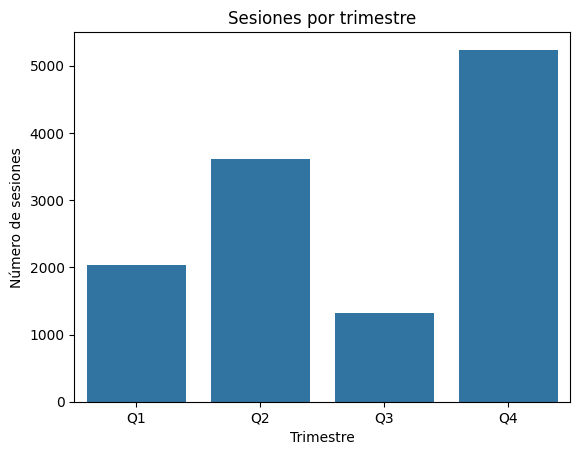

In [ ]:
orden = ['Q1', 'Q2', 'Q3', 'Q4']

sns.countplot(
    data=df,
    x='Trimestre',
    order=orden
)

plt.title('Sesiones por trimestre')
plt.xlabel('Trimestre')
plt.ylabel('Número de sesiones')
plt.show()

### Observaciones de las sesiones por trimestre

Al agrupar las sesiones por trimestre se observa que el cuarto trimestre concentra la mayor cantidad de registros del dataset.

Esta distribución está influida especialmente por los meses de noviembre y diciembre.

## Observaciones de las variables generadas

Durante el preprocesamiento se generaron 4 características adicionales a partir de las variables existentes, con el objetivo de representar de manera más resumida el comportamiento de navegación.

`Avg_Tiempo_Producto` permite conocer el tiempo promedio dedicado a cada página de productos visitada.

`Total_paginasVisitadas` reúne la cantidad de páginas administrativas, informativas y de productos consultadas durante una sesión.

`Duracion_Total` representa la suma del tiempo registrado en las tres categorías de páginas, permitiendo analizar la duración acumulada de navegación.

Finalmente, `Trimestre` agrupa los meses en cuatro periodos del año, facilitando la comparación de la actividad entre periodos.

Estas características complementan la información original y pueden utilizarse en experimentos posteriores para estudiar si aportan información relevante a los modelos.

## Comprobaciones finales del conjunto de datos

In [ ]:
# Comprobar las dimensiones finales
print("Dimensiones originales:", df_original.shape)
print("Dimensiones procesadas:", df.shape)

# Comprobar valores faltantes
print("\nValores faltantes:", df.isna().sum().sum())

# Comprobar duplicados
print("Filas duplicadas:", df.duplicated().sum())

# Comprobar valores infinitos
numericas_finales = df.select_dtypes(include=np.number)

print("Valores infinitos:",
      np.isinf(numericas_finales).sum().sum())

# Revisar los tipos de datos
df.info()

Dimensiones originales: (12330, 18)
Dimensiones procesadas: (12205, 22)

Valores faltantes: 0
Filas duplicadas: 0
Valores infinitos: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12205 entries, 0 to 12204
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   Administrative           12205 non-null  int64   
 1   Administrative_Duration  12205 non-null  float64 
 2   Informational            12205 non-null  int64   
 3   Informational_Duration   12205 non-null  float64 
 4   ProductRelated           12205 non-null  int64   
 5   ProductRelated_Duration  12205 non-null  float64 
 6   BounceRates              12205 non-null  float64 
 7   ExitRates                12205 non-null  float64 
 8   PageValues               12205 non-null  float64 
 9   SpecialDay               12205 non-null  category
 10  Month                    12205 non-null  object  
 11  OperatingSystems         12205 non-n

### Observaciones de las comprobaciones finales

Se realizó una revisión final del conjunto de datos después de eliminar las filas duplicadas adicionales y generar las nuevas características.

Esta comprobación permitió revisar las dimensiones del dataset, los tipos de variables y la posible presencia de valores faltantes, infinitos o duplicados.

También se verificó la estructura de las variables derivadas para confirmar que estuvieran disponibles antes de preparar los modelos de minería de datos.

El conjunto resultante conserva las variables originales y las nuevas características propuestas para representar el comportamiento de navegación.

### **Guardar el dataset preparado**

In [ ]:
from pathlib import Path

# Carpeta de salida
carpeta_salida = Path('/content/drive/MyDrive/mineriaDatos')
carpeta_salida.mkdir(parents=True, exist_ok=True)

# Guardar el dataset procesado
ruta_csv = carpeta_salida / 'online_shoppers__actualizado.csv'

df.to_csv(ruta_csv, index=False)

print("Dataset guardado correctamente.")
print("Archivo:", ruta_csv)
print("Dimensiones:", df.shape)

Dataset guardado correctamente.
Archivo: /content/drive/MyDrive/mineriaDatos/online_shoppers__actualizado.csv
Dimensiones: (12205, 22)
